## **Crime Incidents Data Cleanning**

## Load Lib & Raw Data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
df = pd.read_csv("crime_incidents_messy.csv")


FileNotFoundError: [Errno 2] No such file or directory: 'crime_incidents_messy.csv'

## Explore Data

In [ ]:
df.head()

,incident_id,crime_type,district,city,state,address,latitude,longitude,incident_datetime,officer_id,...,victim_gender,victim_phone,weapon_used,severity,case_status,resolution,num_arrests,property_loss_usd,reported_online,notes
0,INC001115,asslt,Sou,Maplewood,GA,2830 Cedar Lane,170.284100,-77.500710,2024-04-16 08:45:03,OFF0078,...,Unknown,6223265920,Firearm,2,Open,No Arrest,NaN,NaN,True,Incident at 2830 Cedar Lane. Officer responded...
1,INC004706,burglary,southeast,Maplewood,OH,2361 Park Rd,29.422717,-77.167016,2022-01-11 22:03:29,OFF0059,...,NaN,241-973-4826,Firearm,3,NaN,NaN,2.0,44839.49,yes,Incident at 2361 Park Rd. Officer responded at...
2,INC002249,Homocide,Southwest,Lakewood,AZ,1067 Main St,39.411460,-98.615298,2022-04-14 11:39:24,OFF0088,...,Other,244-584-7696,KNIFE,1,CLOSED,warning,2.0,15963.38,YES,Incident at 1067 Main St. Officer responded at...
3,INC000021,Property Damage,Cen,Springfield,AZ,4713 Washington Ave,28.633439,-99.030051,2020-12-09 15:14:24,OFF0077,...,NaN,5021227484,hands,Low,Resolved,NaN,5.0,48680.14,False,Incident at 4713 Washington Ave. Officer respo...
4,INC000488,Domestc Violence,North,Lakewood,PA,1371 River Rd,34.217850,-121.614731,2021-07-24 20:08:13,OFF0083,...,M,9698766873,Unarmed,MEDIUM,Closed,Warning Issued,2.0,23513.01,YES,NaN


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   incident_id         5250 non-null   str    
 1   crime_type          5250 non-null   str    
 2   district            5250 non-null   str    
 3   city                5250 non-null   str    
 4   state               5250 non-null   str    
 5   address             5250 non-null   str    
 6   latitude            4992 non-null   float64
 7   longitude           4961 non-null   float64
 8   incident_datetime   4910 non-null   str    
 9   officer_id          5250 non-null   str    
 10  officer_first_name  5250 non-null   str    
 11  officer_last_name   5250 non-null   str    
 12  badge_number        4938 non-null   float64
 13  suspect_id          4440 non-null   str    
 14  suspect_first_name  4440 non-null   str    
 15  suspect_last_name   4440 non-null   str    
 16  suspect_age      

### Missing Values

<Axes: >

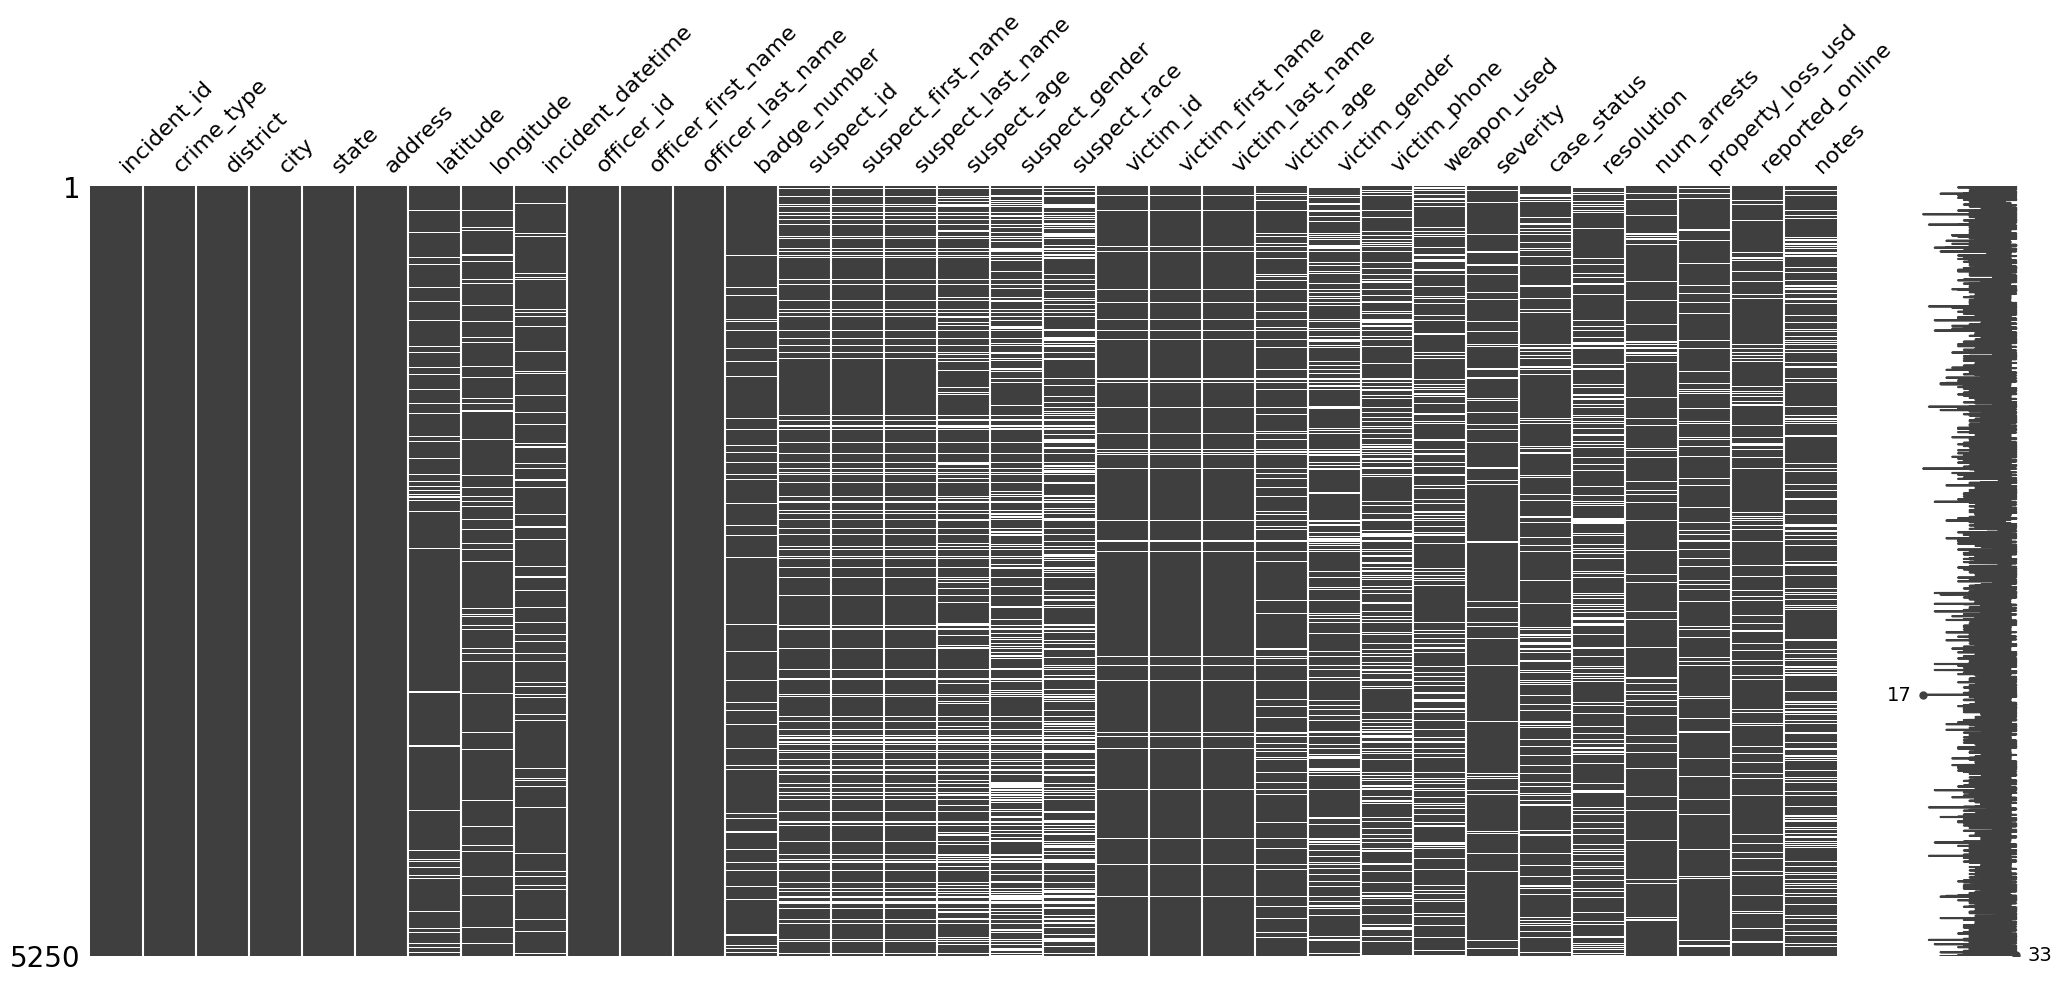

In [ ]:
#  Load The Lib

import missingno as msno
msno.matrix(df)

* No Missing In >> incident_id	| crime_type	| district |	city	| state	address | officer Id + 1st Name + Lanst Name

## Handel Duplicates

In [ ]:
# Duplicates in Pk Column >> incident_id
df['incident_id'].duplicated().sum()

np.int64(200)

In [ ]:
df.duplicated().sum()

np.int64(200)

In [ ]:
df.drop_duplicates(subset='incident_id', inplace=True)
df['incident_id'].duplicated().sum()

np.int64(0)

## Data Type & Formating For **Categorical Columns**


#### Standardization for **All Categorical Columns**

In [ ]:
sorted(df["crime_type"].unique())

['  ASSAULT  ',
 '  Abduction  ',
 '  B&E  ',
 '  Battery  ',
 '  Cybercrime  ',
 '  D.U.I.  ',
 '  DRUG OFFENSE  ',
 '  DUI  ',
 '  DUII  ',
 '  DV  ',
 '  DWI  ',
 '  Dom. Violence  ',
 '  Drug Offence  ',
 '  FRAUD  ',
 '  Fraudulent Activity  ',
 '  Graffiti  ',
 '  Hacking  ',
 '  Kidnaping  ',
 '  Larceny  ',
 '  Narcotics  ',
 '  Property Damage  ',
 '  Robbery  ',
 '  SEXUAL ASSAULT  ',
 '  Sex Assault  ',
 '  Sexual Assualt  ',
 '  Stealing  ',
 '  Trespass  ',
 '  Trespassing  ',
 '  Vandalism  ',
 '  burglary  ',
 '  dui  ',
 '  robbery  ',
 '  sexual assault  ',
 '  theft  ',
 '  theft/larceny  ',
 '  vandalism  ',
 'ARMED ROBBERY',
 'ARSON',
 'ASSAULT',
 'Abduction',
 'Armed  Robbery',
 'Armed Robbery',
 'Arsen',
 'Arson',
 'Assault',
 'Assault  &  Battery',
 'Assault & Battery',
 'Asslt',
 'B&E',
 'BURGLARY',
 'BURGLRY',
 'Battery',
 'Breaking & Entering',
 'Burglary',
 'Burglry',
 'CYBER  CRIME',
 'CYBER CRIME',
 'CYBERCRIME',
 'Cyber Crime',
 'Cybercrime',
 'D.U.I.',
 '

In [ ]:
df[df["crime_type"].str.lower() == "theft"]["crime_type"].value_counts()

crime_type
THEFT    67
Theft    55
theft    39
Name: count, dtype: int64

In [ ]:
# No. Unique in Crime Type
df['crime_type'].nunique()

182

**Handel All Categorical/Object Formating with 1 Fun**

In [ ]:
cat_cols = df.select_dtypes("object").columns
df[cat_cols] = df[cat_cols].apply(
    lambda x: x.str.strip().str.replace(r"\s+", " ", regex=True).str.lower().str.title()
)

In [ ]:
df[df["crime_type"].str.lower() == "theft"]["crime_type"].value_counts()

crime_type
Theft    209
Name: count, dtype: int64

#### Standardization for **Crime Type** Column

In [ ]:
# No. Unique in Crime Type
df['crime_type'].nunique()

58

In [ ]:
# Is there any Aliases
sorted(df["crime_type"].unique())

['Abduction',
 'Armed Robbery',
 'Arsen',
 'Arson',
 'Assault',
 'Assault & Battery',
 'Asslt',
 'B&E',
 'Battery',
 'Breaking & Entering',
 'Burglary',
 'Burglry',
 'Cyber Crime',
 'Cybercrime',
 'D.U.I.',
 'Deception',
 'Dom. Violence',
 'Domestc Violence',
 'Domestic Violence',
 'Drug Offence',
 'Drug Offense',
 'Drugs',
 'Drunk Driving',
 'Dui',
 'Duii',
 'Dv',
 'Dwi',
 'Fire Setting',
 'Fraud',
 'Fraudulent Activity',
 'Graffiti',
 'Hacking',
 'Homicide',
 'Homocide',
 'Kidnaping',
 'Kidnapping',
 'Larceny',
 'Manslaughter',
 'Murder',
 'Narcotics',
 'Online Fraud',
 'Property Damage',
 'Robbery',
 'Robbry',
 'Roberry',
 'Sa',
 'Scam',
 'Sex Assault',
 'Sexual Assault',
 'Sexual Assualt',
 'Stealing',
 'Theft',
 'Theft/Larceny',
 'Trespass',
 'Trespassing',
 'Tresspassing',
 'Vandalism',
 'Vandlism']

In [ ]:
# No. Unique in Crime Type Before Mapping
df['crime_type'].nunique()

58

Fuzzy Matching for Crime Type

In [ ]:
from thefuzz import process

standard_crimes = [
    "Assault", "Armed Robbery", "Arson", "Battery", "Breaking & Entering", 
    "Burglary", "Cybercrime", "Deception", "Domestic Violence", "Drug Offense", 
    "DUI", "Fire Setting", "Fraud", "Graffiti", "Hacking", "Homicide", 
    "Kidnapping", "Larceny", "Manslaughter", "Murder", "Narcotics", 
    "Online Fraud", "Property Damage", "Robbery", "Scam", "Sexual Assault", 
    "Stealing", "Theft", "Trespassing", "Vandalism", "Abduction"
]

def fuzzy_match_crime(val, choices=standard_crimes, threshold=80):
    if not isinstance(val, str) or pd.isna(val):
        return val
    match, score = process.extractOne(val, choices)
    return match if score >= threshold else val

df["crime_type"] = df["crime_type"].apply(fuzzy_match_crime)
df["crime_type"].nunique()

36

In [ ]:
# Is there any Aliases
sorted(df["crime_type"].unique())

['Abduction',
 'Armed Robbery',
 'Arson',
 'Assault',
 'B&E',
 'Battery',
 'Breaking & Entering',
 'Burglary',
 'Cybercrime',
 'D.U.I.',
 'DUI',
 'Deception',
 'Domestic Violence',
 'Drug Offense',
 'Drunk Driving',
 'Dv',
 'Dwi',
 'Fire Setting',
 'Fraud',
 'Graffiti',
 'Hacking',
 'Homicide',
 'Kidnapping',
 'Larceny',
 'Manslaughter',
 'Murder',
 'Narcotics',
 'Online Fraud',
 'Property Damage',
 'Robbery',
 'Scam',
 'Sexual Assault',
 'Stealing',
 'Theft',
 'Trespassing',
 'Vandalism']

In [ ]:
# No. Unique in Crime Type after Mapping
df['crime_type'].nunique()

36

#### Standardization for **District** Column

In [ ]:
# No. Unique in district befor Mapping
df['district'].nunique()

16

In [ ]:
# Is there any Aliases
sorted(df["district"].unique())

['Cen',
 'Central',
 'Eas',
 'East',
 'Mid',
 'Midtown',
 'Nor',
 'North',
 'Northeast',
 'Northwest',
 'Sou',
 'South',
 'Southeast',
 'Southwest',
 'Wes',
 'West']

###  District Name Standardization (Fuzzy Matching)

In [ ]:
from thefuzz import process

standard_districts = [
    "Central",
    "East",
    "Midtown",
    "North",
    "Northeast",
    "Northwest",
    "South",
    "Southeast",
    "Southwest",
    "West",
]


def fuzzy_match_district(val, choices=standard_districts, threshold=80):
  if not isinstance(val, str) or pd.isna(val):
    return val
  match, score = process.extractOne(val, choices)
  return match if score >= threshold else val


df["district"] = df["district"].apply(fuzzy_match_district)
df["district"].nunique()

10

In [ ]:
# Is there any Aliases
sorted(df["district"].unique())

['Central',
 'East',
 'Midtown',
 'North',
 'Northeast',
 'Northwest',
 'South',
 'Southeast',
 'Southwest',
 'West']

In [ ]:
# No. Unique in district after Mapping
df['district'].nunique()

10

#### Standardization for **City** Column

In [ ]:
# No. Unique in city befor Mapping
df['city'].nunique()

8

In [ ]:
# Is there any Aliases
sorted(df["city"].unique())

['Centerville',
 'Fairview',
 'Hillcrest',
 'Lakewood',
 'Maplewood',
 'Oakdale',
 'Riverside',
 'Springfield']

#### Standardization for **State** Column

In [ ]:
# No. Unique in city
df['city'].nunique()

8

In [ ]:
# Is there any Aliases
sorted(df["city"].unique())

['Centerville',
 'Fairview',
 'Hillcrest',
 'Lakewood',
 'Maplewood',
 'Oakdale',
 'Riverside',
 'Springfield']

#### Standardization for **Address** Column

In [ ]:
# No. Unique in city
df['address'].nunique()

4895

In [ ]:
# Is there any Aliases
# sorted(df["address"].unique())

In [ ]:
df['address'].isna().sum()

np.int64(0)

#### Standardization for **Officer Id | officer first name | officer last name| Badge number** Column

In [ ]:
# No. Unique in city
df['officer_id'].nunique()

150

In [ ]:
df['officer_id'].isnull().sum()

np.int64(0)

<Axes: >

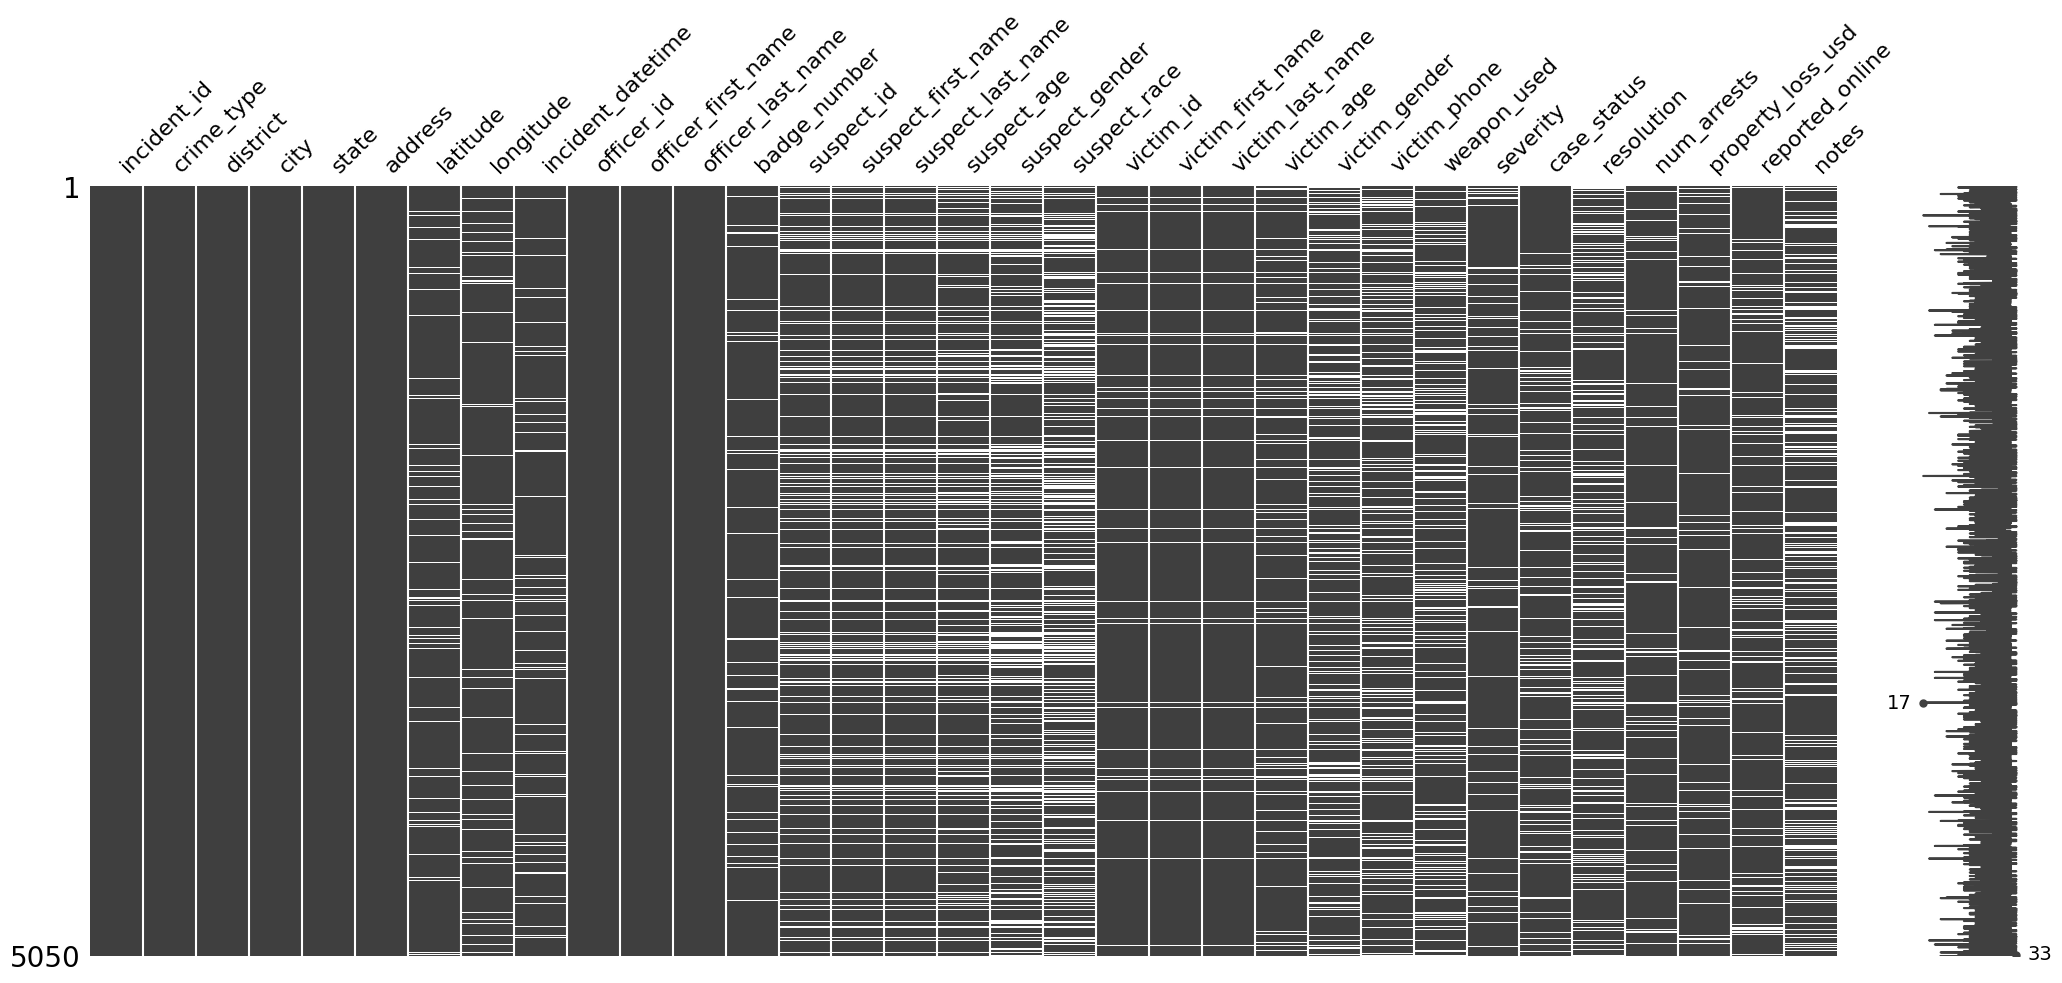

In [ ]:
msno.matrix(df)

#### Standardization for **suspect id** Column

In [ ]:
df['suspect_id'].isnull().sum()

np.int64(775)

In [ ]:
df['suspect_id'] = df['suspect_id'].fillna("Unknown")

In [ ]:
df['suspect_id'].isnull().sum()

np.int64(0)

#### Standardization for **suspect first name** Column

In [ ]:
df['suspect_first_name'].isnull().sum()

np.int64(775)

In [ ]:
df['suspect_first_name'] = df['suspect_first_name'].fillna("Unknown")

In [ ]:
df['suspect_first_name'].isnull().sum()

np.int64(0)

#### Standardization for **suspect last name** Column

In [ ]:
df['suspect_last_name'].isnull().sum()

np.int64(775)

In [ ]:
df['suspect_last_name'] = df['suspect_last_name'].fillna("Unknown")

In [ ]:
df['suspect_first_name'].isnull().sum()

np.int64(0)

#### Standardization for **suspect gender** Column

In [ ]:
# No. Unique in district befor Mapping
df['suspect_gender'].nunique()

6

In [ ]:
# Is there any Aliases
sorted(df["suspect_gender"].dropna().unique())

['F', 'Female', 'M', 'Male', 'Other', 'Unknown']

In [ ]:
df["suspect_gender"].isnull().sum()

np.int64(1352)

In [ ]:
df["suspect_gender"].value_counts()

suspect_gender
Female     922
Male       908
F          656
M          601
Other      306
Unknown    305
Name: count, dtype: int64

In [ ]:
gender_mapping = {
    "F": "Female",
    "M": "Male",
    "Unknow":"Unknown"
}

df["suspect_gender"] = df["suspect_gender"].replace(gender_mapping)
df["suspect_gender"] = df["suspect_gender"].fillna("Unknown")

In [ ]:
# df["suspect_gender"].unique()
df["suspect_gender"].unique()

<ArrowStringArray>
['Male', 'Other', 'Female', 'Unknown']
Length: 4, dtype: str

In [ ]:
df["suspect_gender"].isnull().sum()

np.int64(0)

In [ ]:
df["suspect_gender"].value_counts()

suspect_gender
Unknown    1657
Female     1578
Male       1509
Other       306
Name: count, dtype: int64

#### Standardization for **suspect race** Column

In [ ]:
# No. Unique in district befor Mapping
df['suspect_race'].nunique()

6

In [ ]:
df["suspect_race"] = df["suspect_race"].fillna("Unknown")

In [ ]:
# Is there any Aliases
df["suspect_race"].unique()

<ArrowStringArray>
['Asian', 'Black', 'White', 'Unknown', 'Hispanic', 'Other']
Length: 6, dtype: str

In [ ]:
df['suspect_race'].isnull().sum()

np.int64(0)

#### Standardization for **'victim_id', 'victim_first_name', 'victim_last_name', 'victim_gender', 'weapon_used'** Column

In [ ]:
cols = ['victim_id', 'victim_first_name', 'victim_last_name', 'victim_gender', 'weapon_used']

df[cols].isna().sum()

victim_id            248
victim_first_name    248
victim_last_name     248
victim_gender        963
weapon_used          930
dtype: int64

In [ ]:
df["victim_gender"].unique()

<ArrowStringArray>
['Unknown', nan, 'Other', 'M', 'Female', 'Male', 'F']
Length: 7, dtype: str

In [ ]:
mapping = {
    'M': 'Male',
    'F': 'Female',
    'M': 'Male',
    'F': 'Female',
    'Other': 'Other',
    'Unknown': 'Unknown'
}

df['victim_gender'] = df['victim_gender'].replace(mapping)

In [ ]:
df["victim_gender"].unique()

<ArrowStringArray>
['Unknown', nan, 'Other', 'Male', 'Female']
Length: 5, dtype: str

In [ ]:
cols = ['victim_id', 'victim_first_name', 'victim_last_name', 'victim_gender', 'weapon_used', 'case_status', 'resolution']

df[cols] = df[cols].fillna("Unknown")
df[cols].isna().sum()

victim_id            0
victim_first_name    0
victim_last_name     0
victim_gender        0
weapon_used          0
case_status          0
resolution           0
dtype: int64

In [ ]:
df["victim_gender"].unique()

<ArrowStringArray>
['Unknown', 'Other', 'Male', 'Female']
Length: 4, dtype: str

In [ ]:
sorted(df['case_status'].dropna().unique())

['Closed',
 'Investgation',
 'Open',
 'Pending',
 'Pendng',
 'Resolved',
 'Under Investigation',
 'Unknown']

In [ ]:
mapping = {
    'Pendng': 'Pending',
    'Under Investigation':'Investgation'
}

df['case_status'] = df['case_status'].replace(mapping)

In [ ]:
sorted(df['case_status'].dropna().unique())

['Closed', 'Investgation', 'Open', 'Pending', 'Resolved', 'Unknown']

In [ ]:
sorted(df['resolution'].dropna().unique())

['Arres Made',
 'Arrest Made',
 'Case Dismissed',
 'Dismissed',
 'No Arrest',
 'Unknown',
 'Warning',
 'Warning Issued']

In [ ]:
resolution_mapping = {
    "Arres Made": "Arrest Made",
    "Arrest Made": "Arrest Made",
    "Case Dismissed": "Dismissed",
    "Dismissed": "Dismissed",
    "No Arrest": "No Arrest",
    "Unknown": "Unknown",
    "Warning": "Warning Issued",
    "Warning Issued": "Warning Issued"
}

df["resolution"] = df["resolution"].map(resolution_mapping)

In [ ]:
sorted(df['resolution'].dropna().unique())

['Arrest Made', 'Dismissed', 'No Arrest', 'Unknown', 'Warning Issued']

#### Standardization for **reported_online** Column | **boolean column**

In [ ]:
df["reported_online"].unique()

<ArrowStringArray>
['True', 'Yes', 'False', 'No', nan, '1', '0']
Length: 7, dtype: str

In [ ]:
df["reported_online"] = df["reported_online"].replace({
    "True": True, "Yes": True, "1": True,
    "False": False, "No": False, "0": False
}).fillna("Unknown")

In [ ]:
df["reported_online"].unique()

array([True, False, 'Unknown'], dtype=object)

In [ ]:
df["reported_online"].isnull().sum()

np.int64(0)

#### Standardization for **vivtim_phone** Column

In [ ]:
df['victim_phone'].describe()

count             4031
unique            3994
top       599-946-4741
freq                 2
Name: victim_phone, dtype: object

In [ ]:
df['victim_phone'].head(10)

0      6223265920
1    241-973-4826
2    244-584-7696
3      5021227484
4      9698766873
5    590-332-6488
6    431-579-6170
7    587-505-1798
8      3956212676
9    376-440-3132
Name: victim_phone, dtype: str

In [ ]:
clean_phone = df["victim_phone"].astype(str).str.replace(r"\D", "", regex=True)
df["victim_phone"] = pd.to_numeric(clean_phone, errors="coerce").astype("Int64")

In [ ]:
df['victim_phone'].head(10)

0    6223265920
1    2419734826
2    2445847696
3    5021227484
4    9698766873
5    5903326488
6    4315796170
7    5875051798
8    3956212676
9    3764403132
Name: victim_phone, dtype: Int64

#### Standardization for **severity** Column

In [ ]:
df["severity"].unique()

<ArrowStringArray>
['2', '3', '1', 'Low', 'Medium', 'High', nan, 'Crit', 'Critical', '4', 'Med']
Length: 11, dtype: str

In [ ]:
df["severity"].isnull().sum()

np.int64(342)

In [ ]:
severity_map = {
    '1': 'Low',
    '2': 'Medium',
    '3': 'High',
    '4': 'critical',
    'med': 'Medium',
    'Med': 'Medium',
    'medium': 'Medium',
    'low': 'Low',
    'high': 'High',
    'Medium': 'Medium',
    'crit': 'Critical',
    'Crit': 'Critical',
    'criticl': 'Critical',
    'critical': 'Critical'
}

df['severity'] = df['severity'].replace(severity_map).fillna('Unknown')
df['severity'].unique()

<ArrowStringArray>
['Medium', 'High', 'Low', 'Unknown', 'Critical', 'critical']
Length: 6, dtype: str

In [ ]:
df["severity"].isnull().sum()

np.int64(0)

### Drop Column **Notes**

In [ ]:
df.drop(columns="notes", inplace=True, errors="ignore")

## Group By


#### Group By for r **victim_gender** 

In [ ]:
df["victim_gender"].value_counts()

victim_gender
Male       1751
Female     1615
Unknown    1330
Other       354
Name: count, dtype: int64

In [ ]:
gender_mode = (df[df["victim_gender"] != "Unknown"].groupby(["crime_type","district"])["victim_gender"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
)
gender_mode2 = (df[df["victim_gender"]!= "Unknown" ].groupby("crime_type")["victim_gender"]
    .agg(lambda x:x.mode().iloc[0] if not x.mode().empty else "UnKnown")          
    
)
mask =df["victim_gender"] == "Unknown"
df.loc[mask,"victim_gender"] = (df.loc[mask, ["crime_type", "district"]].apply(tuple , axis=1).map(gender_mode) 
    .fillna( df.loc[mask, "crime_type"].map(gender_mode2) ).fillna("Unknown"))
df["victim_gender"] = df["victim_gender"].fillna("Unknown")


In [ ]:
df["victim_gender"].value_counts()

victim_gender
Male      2358
Female    2313
Other      379
Name: count, dtype: int64

#### Group By for **suspect gender** 

In [ ]:
df["suspect_gender"].value_counts()

suspect_gender
Unknown    1657
Female     1578
Male       1509
Other       306
Name: count, dtype: int64

In [ ]:
gender_mode_sus = (df[df["suspect_gender"] != "Unknown"].groupby(["crime_type","district"])["suspect_gender"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
)
gender_mode2_sus = (df[df["suspect_gender"]!= "Unknown" ].groupby("crime_type")["suspect_gender"]
    .agg(lambda x:x.mode().iloc[0] if not x.mode().empty else "UnKnown")          
    
)
mask =df["suspect_gender"] == "Unknown"
df.loc[mask,"suspect_gender"] = (df.loc[mask, ["crime_type", "district"]].apply(tuple , axis=1).map(gender_mode_sus) 
    .fillna( df.loc[mask, "crime_type"].map(gender_mode2_sus) ).fillna("Unknown"))
df["suspect_gender"] = df["suspect_gender"].fillna("Unknown")



In [ ]:
df["suspect_gender"].value_counts()

suspect_gender
Female    2544
Male      2191
Other      315
Name: count, dtype: int64

#### Group By for **severity** 

In [ ]:
df["severity"].value_counts()

severity
Medium      1349
Low         1032
High         990
Critical     968
critical     369
Unknown      342
Name: count, dtype: int64

In [ ]:
severity_mode = (
    df[df["severity"] != "Unknown"]
    .groupby("district")["severity"]
    .agg(lambda x: x.mode().iloc[0])
)
mask = df["severity"] == "Unknown"

df.loc[mask, "severity"] = (
    df.loc[mask, "district"].map(severity_mode)
)

In [ ]:
df["severity"].value_counts()

severity
Medium      1691
Low         1032
High         990
Critical     968
critical     369
Name: count, dtype: int64

#### Group By for **weapon used** 

In [ ]:
df["weapon_used"].value_counts()

weapon_used
Unknown         930
Knife           646
Blunt Object    640
Firearm         600
Hands/Feet      354
Unarmed         344
Rifle           334
Hands           305
Gun             304
Pistol          301
Bat             292
Name: count, dtype: int64

In [ ]:
weapon_mode = (df[df["weapon_used"] != "Unknown"].groupby(["crime_type","district"])["weapon_used"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
)
weapon_mode2 = (df[df["weapon_used"]!= "Unknown" ].groupby("crime_type")["weapon_used"]
    .agg(lambda x:x.mode().iloc[0] if not x.mode().empty else "UnKnown")          
    
)
mask =df["weapon_used"] == "Unknown"
df.loc[mask,"weapon_used"] = (df.loc[mask, ["crime_type", "district"]].apply(tuple , axis=1).map(weapon_mode) 
    .fillna( df.loc[mask, "crime_type"].map(weapon_mode2) ).fillna("Unknown"))
df["weapon_used"] = df["weapon_used"].fillna("Unknown")



In [ ]:
df["weapon_used"].value_counts()

weapon_used
Blunt Object    922
Knife           848
Firearm         807
Unarmed         374
Hands/Feet      372
Rifle           368
Bat             357
Hands           348
Gun             341
Pistol          313
Name: count, dtype: int64

#### Group By for r **case_status** 

In [ ]:
df["case_status"].value_counts()

case_status
Closed          1099
Open            1096
Investgation    1073
Pending          713
Unknown          696
Resolved         373
Name: count, dtype: int64

In [ ]:
case_status_mode = (df[df["case_status"] != "Unknown"].groupby(["crime_type","district"])["case_status"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
)
case_status_mode2 = (df[df["case_status"]!= "Unknown" ].groupby("crime_type")["case_status"]
    .agg(lambda x:x.mode().iloc[0] if not x.mode().empty else "UnKnown")          
    
)
mask =df["case_status"] == "Unknown"
df.loc[mask,"case_status"] = (df.loc[mask, ["crime_type", "district"]].apply(tuple , axis=1).map(case_status_mode) 
    .fillna( df.loc[mask, "crime_type"].map(case_status_mode2) ).fillna("Unknown"))
df["case_status"] = df["case_status"].fillna("Unknown")



In [ ]:
df["case_status"].value_counts()

case_status
Closed          1377
Investgation    1274
Open            1262
Pending          761
Resolved         376
Name: count, dtype: int64

#### Group By for  **resolution** 

In [ ]:
df["resolution"].value_counts()

resolution
Arrest Made       1401
Warning Issued     939
Unknown            912
Dismissed          902
No Arrest          896
Name: count, dtype: int64

In [ ]:
resolution_mode = (df[df["resolution"] != "Unknown"].groupby(["crime_type","case_status"])["resolution"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
)
resolution_mode2 = (df[df["resolution"]!= "Unknown" ].groupby("crime_type")["resolution"]
    .agg(lambda x:x.mode().iloc[0] if not x.mode().empty else "UnKnown")          
    
)
mask =df["resolution"] == "Unknown"
df.loc[mask,"resolution"] = (df.loc[mask, ["crime_type", "district"]].apply(tuple , axis=1).map(resolution_mode) 
    .fillna( df.loc[mask, "crime_type"].map(resolution_mode2) ).fillna("Unknown"))
df["resolution"] = df["resolution"].fillna("Unknown")



In [ ]:
df["resolution"].value_counts()

resolution
Arrest Made       2224
Warning Issued     965
Dismissed          949
No Arrest          912
Name: count, dtype: int64

## Data Type & Formating For **Numeric Columns**


#### Standardization for **Latitude | Lognitude** Column

In [ ]:
# df["latitude"] = df["latitude"].where(df["latitude"].between(-90, 90))
df["latitude"] = df["latitude"].where(df["latitude"].between(24, 49))

In [ ]:
df["latitude"].isnull().sum()

np.int64(427)

In [ ]:
df["longitude"].isnull().sum()

np.int64(278)

In [ ]:
# df["longitude"] = df["longitude"].where(df["longitude"].between(-180, 180))
df["longitude"] = df["longitude"].where(df["longitude"].between(-125, -67))

In [ ]:
df["longitude"].isnull().sum()

np.int64(474)

#### Standardization for **incident_datetime** Column




In [ ]:
df["incident_datetime"].info()


<class 'pandas.Series'>
Index: 5050 entries, 0 to 5249
Series name: incident_datetime
Non-Null Count  Dtype
--------------  -----
4721 non-null   str  
dtypes: str(1)
memory usage: 165.1 KB


In [ ]:
df["incident_datetime"].head(20)


0     2024-04-16 08:45:03
1     2022-01-11 22:03:29
2     2022-04-14 11:39:24
3     2020-12-09 15:14:24
4     2021-07-24 20:08:13
5              05-03-2020
6     2021-10-03 05:17:02
7     2023-09-30 14:49:01
8     2021-01-22 02:37:24
9     2021-03-29 04:16:18
10    2020-03-03 06:46:12
11    2018-09-09 02:11:36
12    2020-07-04 13:31:15
13    2023-07-30 09:05:34
14       04/01/2020 03:09
15    2020-11-26 07:15:19
16    2021-11-05 17:21:18
17    2022-10-07 17:15:25
18    2024-11-23 19:30:48
19    2018-08-26 04:50:54
Name: incident_datetime, dtype: str

In [ ]:
# incident_datetime.to.datetime
df['incident_datetime']= pd.to_datetime(df['incident_datetime'],format='mixed')
df["incident_datetime"].info()
df['incident_datetime'].head(20)

<class 'pandas.Series'>
Index: 5050 entries, 0 to 5249
Series name: incident_datetime
Non-Null Count  Dtype         
--------------  -----         
4721 non-null   datetime64[us]
dtypes: datetime64[us](1)
memory usage: 78.9 KB


0    2024-04-16 08:45:03
1    2022-01-11 22:03:29
2    2022-04-14 11:39:24
3    2020-12-09 15:14:24
4    2021-07-24 20:08:13
5    2020-05-03 00:00:00
6    2021-10-03 05:17:02
7    2023-09-30 14:49:01
8    2021-01-22 02:37:24
9    2021-03-29 04:16:18
10   2020-03-03 06:46:12
11   2018-09-09 02:11:36
12   2020-07-04 13:31:15
13   2023-07-30 09:05:34
14   2020-04-01 03:09:00
15   2020-11-26 07:15:19
16   2021-11-05 17:21:18
17   2022-10-07 17:15:25
18   2024-11-23 19:30:48
19   2018-08-26 04:50:54
Name: incident_datetime, dtype: datetime64[us]

In [ ]:
df["incident_datetime"].isnull().sum()

np.int64(329)

In [ ]:
df['incident_datetime'] = df['incident_datetime'].ffill()

In [ ]:
df["incident_datetime"].isnull().sum()

np.int64(0)

In [ ]:
df["incident_time"] = df["incident_datetime"].dt.strftime("%H:%M:%S")
df["incident_hour"] = df["incident_datetime"].dt.hour
df["incident_year"] = df["incident_datetime"].dt.year
df["incident_month"] = df["incident_datetime"].dt.month
df["incident_day"] = df["incident_datetime"].dt.day

In [ ]:
df[["incident_time","incident_hour", "incident_month", "incident_year", "incident_day"]].head()

,incident_time,incident_hour,incident_month,incident_year,incident_day
0,08:45:03,8,4,2024,16
1,22:03:29,22,1,2022,11
2,11:39:24,11,4,2022,14
3,15:14:24,15,12,2020,9
4,20:08:13,20,7,2021,24


#### Standardization for **badge_number** Column




In [ ]:
df["badge_number"].info()


<class 'pandas.Series'>
Index: 5050 entries, 0 to 5249
Series name: badge_number
Non-Null Count  Dtype  
--------------  -----  
4749 non-null   float64
dtypes: float64(1)
memory usage: 78.9 KB


In [ ]:
result = df.groupby("officer_id")["badge_number"].nunique()

print(result.head(20))

officer_id
Off0001    35
Off0002    25
Off0003    38
Off0004    31
Off0005    25
Off0006    31
Off0007    29
Off0008    49
Off0009    32
Off0010    32
Off0011    37
Off0012    40
Off0013    18
Off0014    40
Off0015    45
Off0016    22
Off0017    27
Off0018    32
Off0019    40
Off0020    33
Name: badge_number, dtype: int64


In [ ]:
df['badge_number'].isna().sum()

np.int64(301)

In [ ]:
df["badge_number"] = df["badge_number"].astype("object").fillna("Unknown")

In [ ]:
df["badge_number"].info()


<class 'pandas.Series'>
Index: 5050 entries, 0 to 5249
Series name: badge_number
Non-Null Count  Dtype 
--------------  ----- 
5050 non-null   object
dtypes: object(1)
memory usage: 78.9+ KB


In [ ]:
df['badge_number'].isna().sum()

np.int64(0)

#### Handaling for **Age** Columns




suspect_age

In [ ]:
df['suspect_age'].isna().sum()

np.int64(1052)

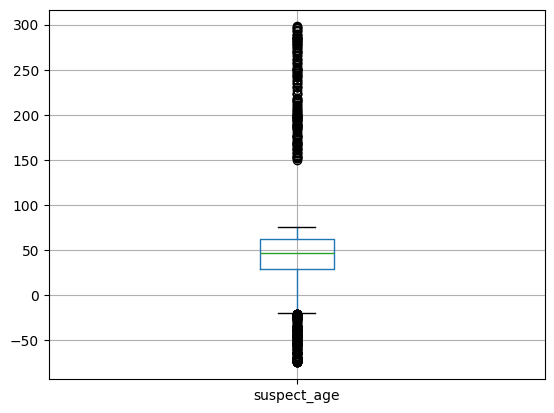

In [ ]:
df.boxplot(column='suspect_age')
plt.show()

In [ ]:
df["suspect_age"] = df["suspect_age"].where(df["suspect_age"].between(0, 100))
df['suspect_age'].isna().sum()

np.int64(1375)

In [ ]:
# def outliers(columns):
#   Q1 = columns.quantile(0.25)
#   Q3 = columns.quantile(0.75)
#   IQR = Q3 - Q1
#   Lower_Bound= Q1 - 1.5 * IQR
#   Upper_Bound= Q3 + 1.5 * IQR
#   return columns.clip(
#       lower= Lower_Bound,
#       upper= Upper_Bound
#   )

# num_cols = ['suspect_age']
# df[num_cols] = df[num_cols].apply(outliers)

In [ ]:
df['suspect_age'].describe()

count    3675.000000
mean       45.429932
std        17.449443
min        15.000000
25%        31.000000
50%        46.000000
75%        60.000000
max        75.000000
Name: suspect_age, dtype: float64

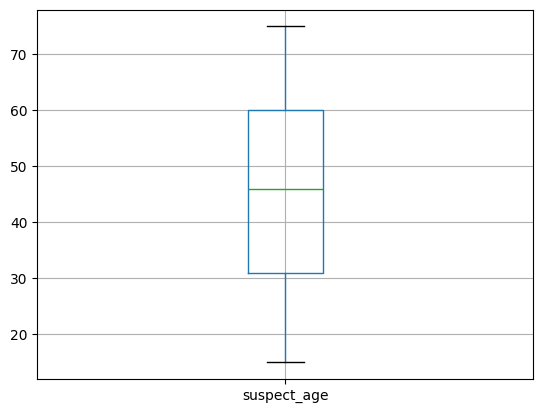

In [ ]:
df.boxplot(column='suspect_age')
plt.show()

In [ ]:
df['suspect_age'].describe()

count    3675.000000
mean       45.429932
std        17.449443
min        15.000000
25%        31.000000
50%        46.000000
75%        60.000000
max        75.000000
Name: suspect_age, dtype: float64

In [ ]:
df['suspect_age'] = df['suspect_age'].fillna(df['suspect_age'].median())
df['suspect_age'].isnull().sum()

np.int64(0)

victim_age

In [ ]:
df['victim_age'].describe()

count    4508.000000
mean       52.228039
std        47.832059
min       -90.000000
25%        27.000000
50%        49.000000
75%        71.000000
max       298.000000
Name: victim_age, dtype: float64

In [ ]:
df['victim_age'].isna().sum()

np.int64(542)

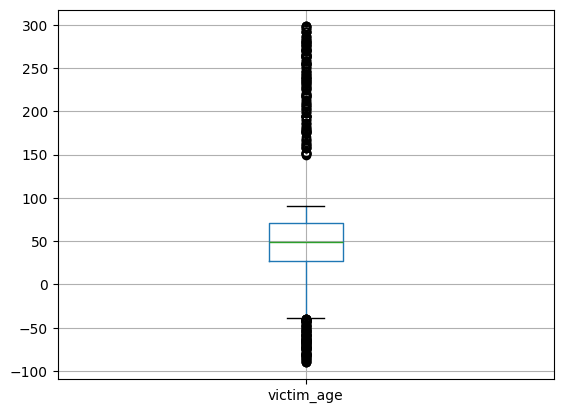

In [ ]:
df['victim_age'].isna().sum()
df.boxplot(column='victim_age')
plt.show()

In [ ]:
df['victim_age'].describe()

count    4508.000000
mean       52.228039
std        47.832059
min       -90.000000
25%        27.000000
50%        49.000000
75%        71.000000
max       298.000000
Name: victim_age, dtype: float64

In [ ]:
# def outliers(columns):
#   Q1 = columns.quantile(0.25)
#   Q3 = columns.quantile(0.75)
#   IQR = Q3 - Q1
#   Lower_Bound= Q1 - 1.5 * IQR
#   Upper_Bound= Q3 + 1.5 * IQR
#   return columns.clip(
#       lower= Lower_Bound,
#       upper= Upper_Bound
#   )

# num_cols = ['victim_age']
# df[num_cols] = df[num_cols].apply(outliers)

In [ ]:
df["victim_age"] = df["victim_age"].where( df["victim_age"].between(0, 100))
df['victim_age'].isna().sum()

np.int64(931)

In [ ]:
df['victim_age'].describe()

count    4119.000000
mean       49.881525
std        23.309186
min        10.000000
25%        30.000000
50%        50.000000
75%        70.000000
max        90.000000
Name: victim_age, dtype: float64

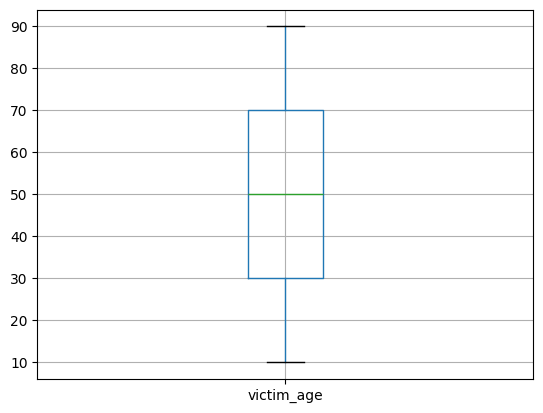

In [ ]:
df.boxplot(column='victim_age')
plt.show()

In [ ]:
df['victim_age'] = df['victim_age'].fillna(df['victim_age'].median())
df['victim_age'].isnull().sum()

np.int64(0)

#### Handaling **num_arrests** Column *Ask instructor*

In [ ]:
df['num_arrests'].isnull().sum()

np.int64(324)

In [ ]:
sorted(df["num_arrests"].unique())

[np.float64(nan),
 np.float64(-5.0),
 np.float64(-4.0),
 np.float64(-3.0),
 np.float64(-2.0),
 np.float64(-1.0),
 np.float64(0.0),
 np.float64(1.0),
 np.float64(2.0),
 np.float64(3.0),
 np.float64(4.0),
 np.float64(5.0)]

In [ ]:
df["num_arrests"] = (
    pd.to_numeric(df["num_arrests"], errors="coerce").abs().astype("Int64")
)

In [ ]:
df['num_arrests'].unique()

<IntegerArray>
[<NA>, 2, 5, 1, 3, 0, 4]
Length: 7, dtype: Int64

In [ ]:
df["num_arrests"].isna().sum()

np.int64(324)

In [ ]:
df['num_arrests'] = df['num_arrests'].fillna(df['num_arrests'].mode()[0])
df['num_arrests'].isnull().sum()

np.int64(0)

property_loss_usd

In [ ]:
df["property_loss_usd"].isna().sum()

np.int64(414)

In [ ]:
#  From Object to Int type
df["property_loss_usd"] = pd.to_numeric(df["property_loss_usd"],errors="coerce")

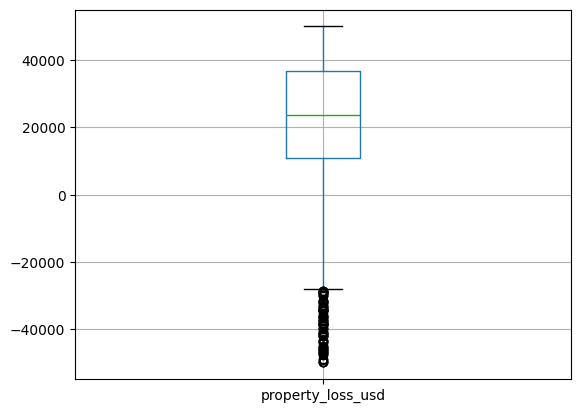

In [ ]:
df.boxplot(column='property_loss_usd')
plt.show()

In [ ]:
df["property_loss_usd"].info()

<class 'pandas.Series'>
Index: 5050 entries, 0 to 5249
Series name: property_loss_usd
Non-Null Count  Dtype  
--------------  -----  
4500 non-null   float64
dtypes: float64(1)
memory usage: 78.9 KB


In [ ]:
df['property_loss_usd'].describe()

count     4500.000000
mean     22774.688522
std      17586.027302
min     -49866.740000
25%      10775.627500
50%      23630.900000
75%      36796.007500
max      49998.300000
Name: property_loss_usd, dtype: float64

In [ ]:
df["property_loss_usd"] = pd.to_numeric(df["property_loss_usd"], errors="coerce").abs()

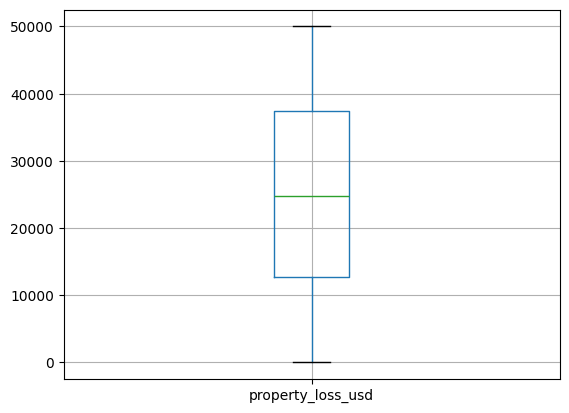

In [ ]:
df.boxplot(column='property_loss_usd')
plt.show()

In [ ]:
df["property_loss_usd"].isna().sum()

np.int64(550)

In [ ]:
df['property_loss_usd'] = df['property_loss_usd'].fillna(df['property_loss_usd'].median())
df['property_loss_usd'].isnull().sum()

np.int64(0)

<Axes: >

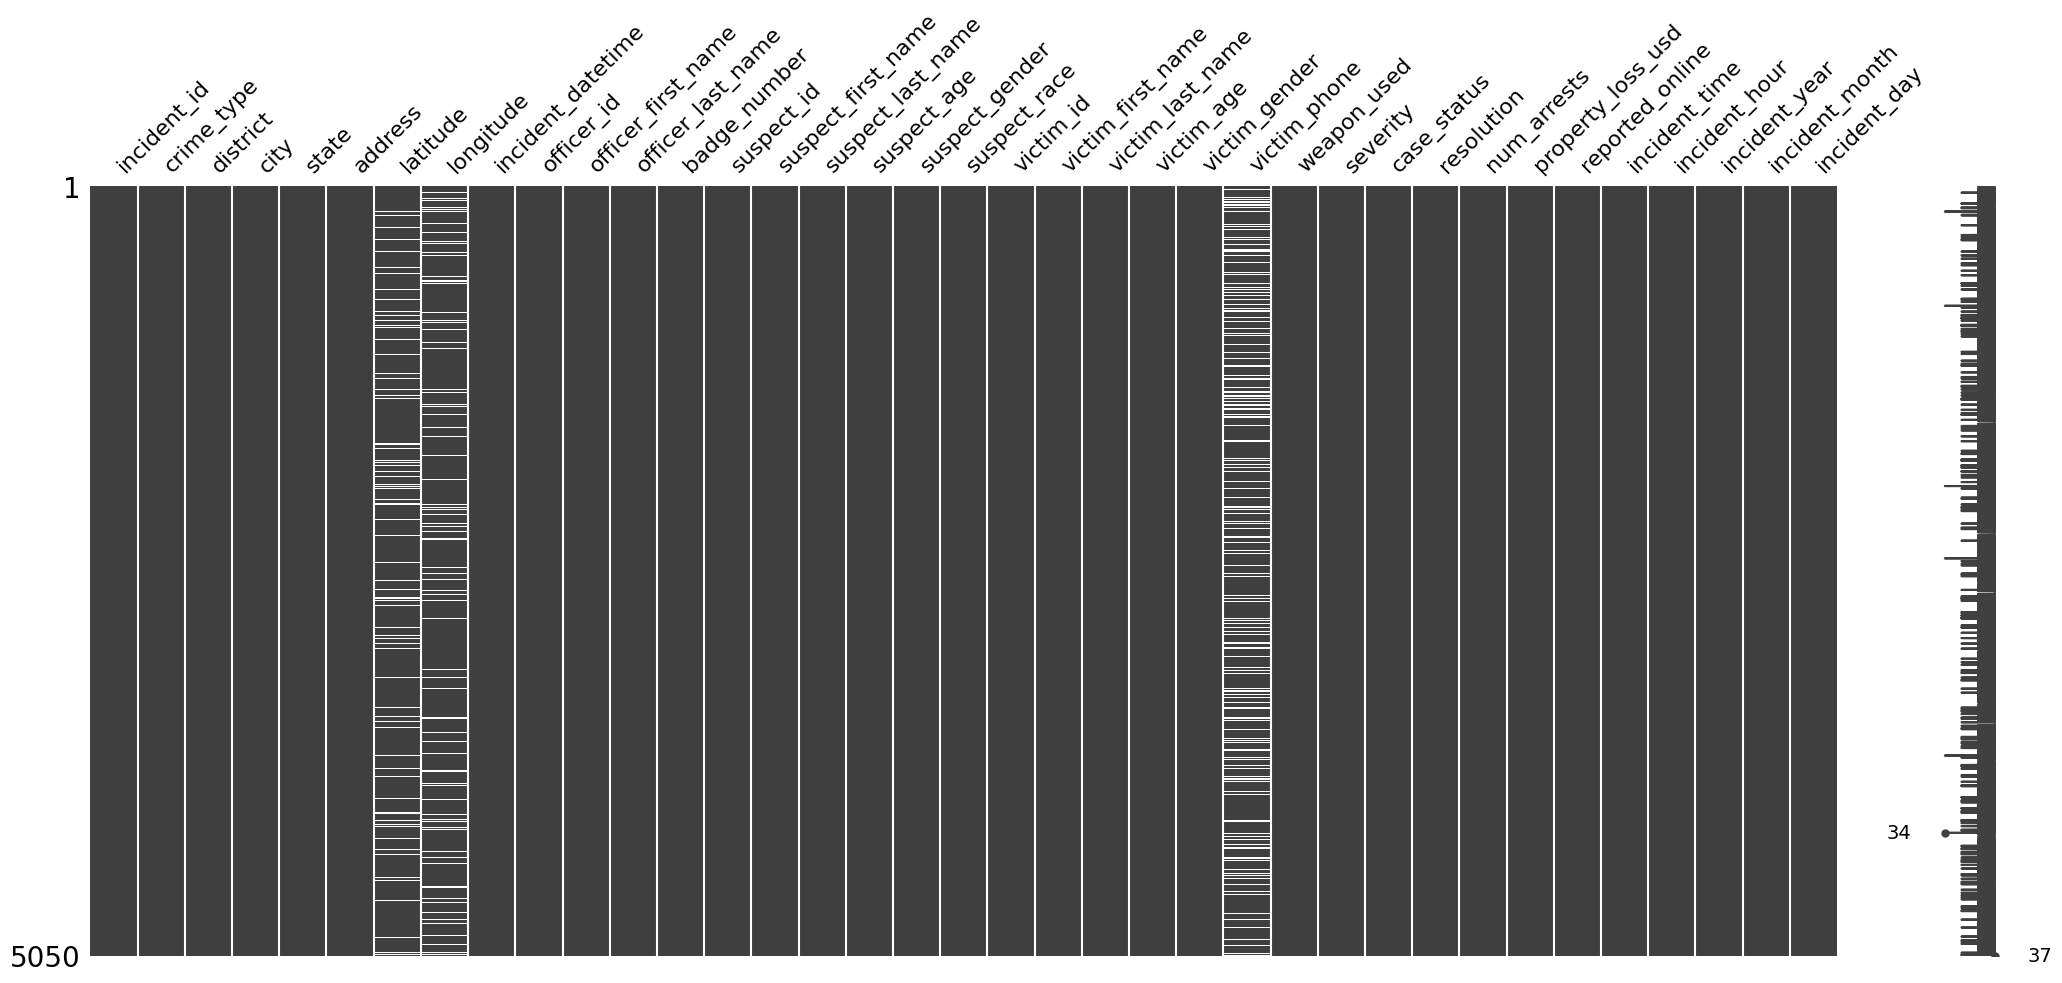

In [ ]:
msno.matrix(df)

### Pattern Discovery Using K-Means Clustering


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df['incident_datetime'] = pd.to_datetime(df['incident_datetime'], errors='coerce')
df['incident_hour'] = df['incident_datetime'].dt.hour.fillna(df['incident_datetime'].dt.hour.median())

features = ['latitude', 'longitude', 'incident_hour', 'property_loss_usd']
cluster_df = df[features].dropna()

scaler = StandardScaler()
scaled_features = scaler.fit_transform(cluster_df)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df.loc[cluster_df.index, 'crime_cluster'] = kmeans.fit_predict(scaled_features)

df.groupby('crime_cluster')[['property_loss_usd', 'incident_hour', 'latitude', 'longitude']].mean()

,property_loss_usd,incident_hour,latitude,longitude
crime_cluster,,,,
0.0,25598.804797,14.124517,41.831021,-109.248188
1.0,24613.035037,4.625000,31.472167,-101.306757
2.0,23029.338058,7.676720,41.715492,-82.428335
3.0,25920.136807,17.215475,31.112766,-89.510300


### Interactive Crime Metrics Explorer

In [ ]:
import ipywidgets as widgets

def show_crime_stats(crime_type):
    sub = df[df['crime_type'] == crime_type]
    print(f"Total Incidents: {len(sub)}")
    print(f"Mean Property Loss: ${sub['property_loss_usd'].mean():,.2f}")
    if not sub['district'].empty:
        print(f"Top District: {sub['district'].mode()[0]}")
    if not sub['weapon_used'].empty:
        print(f"Top Weapon: {sub['weapon_used'].mode()[0]}")

crime_dropdown = widgets.Dropdown(
    options=sorted(df['crime_type'].dropna().unique()),
    description='Crime Type:',
    disabled=False
)

widgets.interact(show_crime_stats, crime_type=crime_dropdown);

interactive(children=(Dropdown(description='Crime Type:', options=('Abduction', 'Armed Robbery', 'Arson', 'Ass…

## Data Visualization (Matplotlib)


In [ ]:
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
sns.set_style('whitegrid')
df.shape

(5050, 38)

### 1. Crime Type Distribution

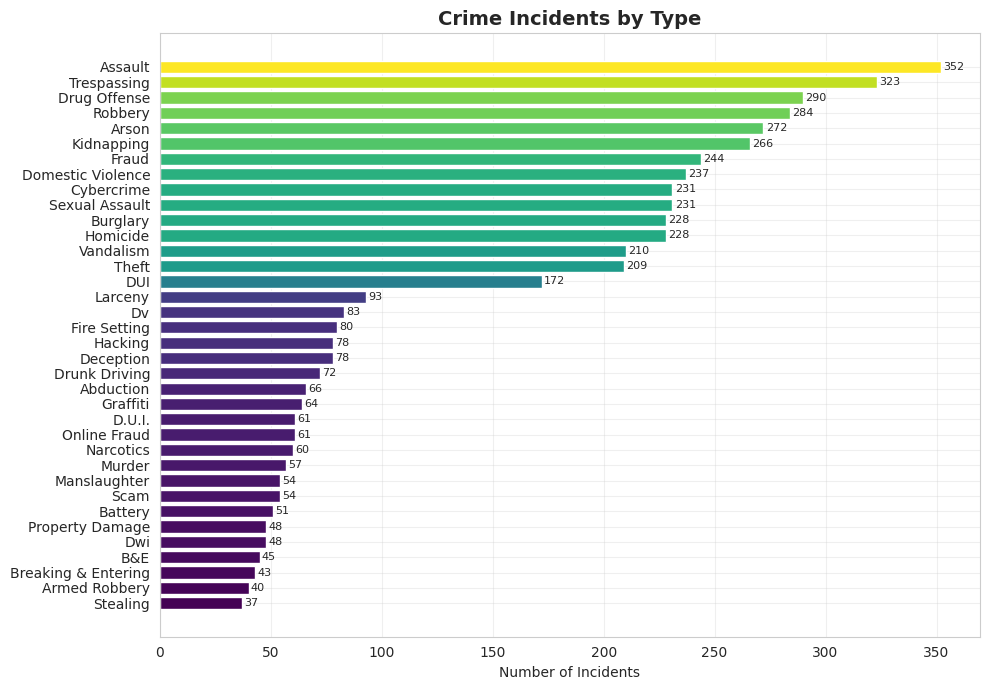

In [ ]:
crime_counts = df['crime_type'].value_counts()

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(crime_counts.index[::-1], crime_counts.values[::-1], color=plt.cm.viridis(
    (crime_counts.values[::-1] - crime_counts.values.min()) / (crime_counts.values.max() - crime_counts.values.min())
))
ax.set_xlabel('Number of Incidents')
ax.set_title('Crime Incidents by Type', fontsize=14, fontweight='bold')
for bar in bars:
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2, f'{int(width)}', va='center', fontsize=8)
plt.tight_layout()
plt.show()

### 2. Incidents Over Time (Yearly & Monthly Trend)

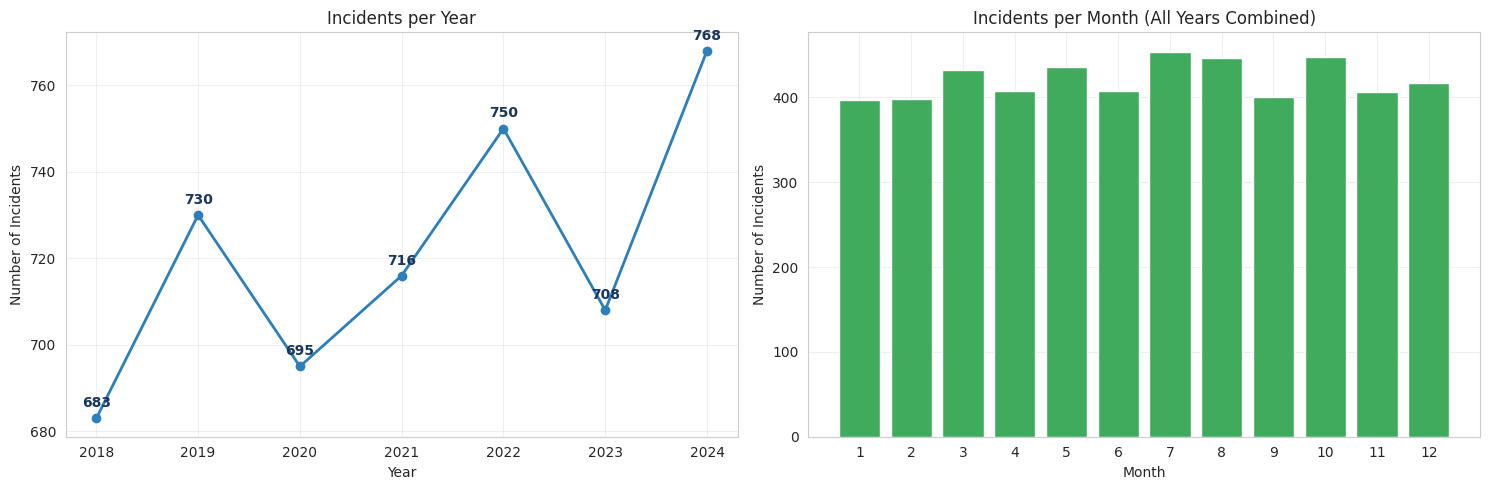

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

yearly = df['incident_year'].value_counts().sort_index()
axes[0].plot(yearly.index, yearly.values, marker='o', color='#2c7fb8', linewidth=2)
axes[0].set_title('Incidents per Year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Incidents')

for x, y in zip(yearly.index, yearly.values):
    axes[0].annotate(f'{int(y)}', 
                     (x, y), 
                     textcoords="offset points", 
                     xytext=(0, 8), 
                     ha='center', 
                     fontweight='bold', 
                     fontsize=10, 
                     color='#1a365d')

monthly = df['incident_month'].value_counts().sort_index()
axes[1].bar(monthly.index, monthly.values, color='#41ab5d')
axes[1].set_title('Incidents per Month (All Years Combined)')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Number of Incidents')
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

### 3. Incidents by Hour of Day

In [ ]:
hourly = df['incident_hour'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(hourly.index, hourly.values, color='#fd8d3c', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Hour of Day (0-23)')
ax.set_ylabel('Number of Incidents')
ax.set_title('Crime Incidents by Hour of Day', fontsize=14, fontweight='bold')
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

### 4. Severity Breakdown

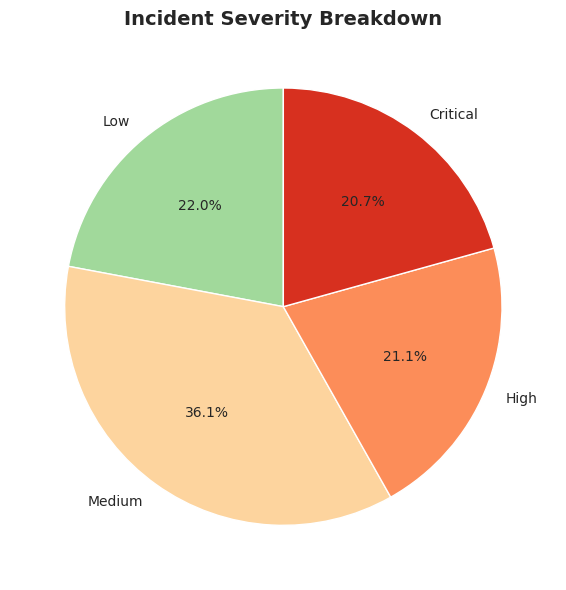

In [ ]:
severity_order = ['Low', 'Medium', 'High', 'Critical']
severity_counts = df['severity'].value_counts().reindex(
    [s for s in severity_order if s in df['severity'].unique()]
).dropna()

colors = {'Low': '#a1d99b', 'Medium': '#fdd49e', 'High': '#fc8d59', 'Critical': '#d7301f'}
fig, ax = plt.subplots(figsize=(8, 6))
ax.pie(severity_counts.values, labels=severity_counts.index, autopct='%1.1f%%',
       colors=[colors.get(s, '#999999') for s in severity_counts.index], startangle=90,
       wedgeprops={'edgecolor': 'white', 'linewidth': 1})
ax.set_title('Incident Severity Breakdown', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 5. Incidents by District

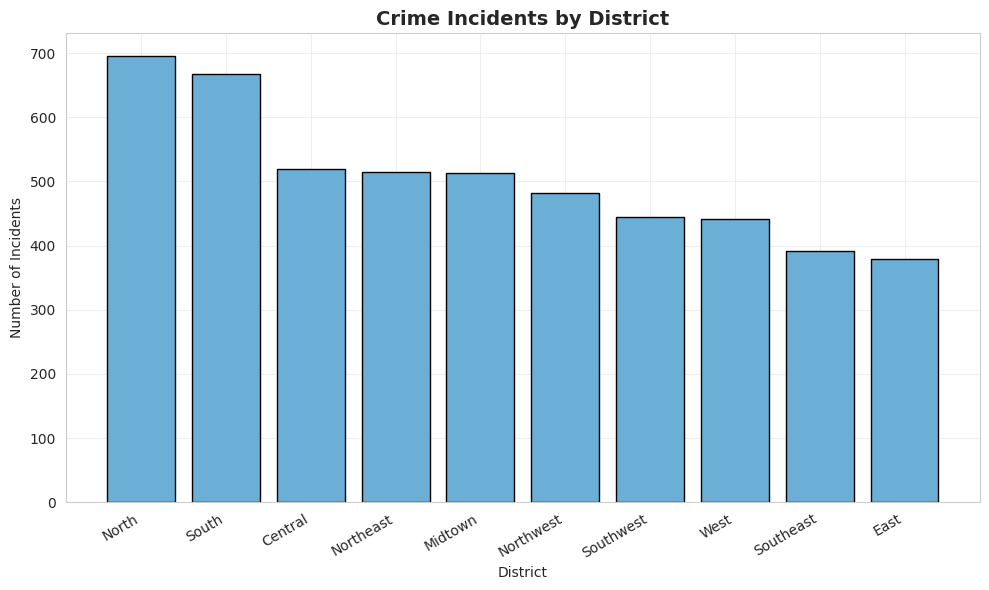

In [ ]:
district_counts = df['district'].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(district_counts.index, district_counts.values, color='#6baed6', edgecolor='black')
ax.set_xlabel('District')
ax.set_ylabel('Number of Incidents')
ax.set_title('Crime Incidents by District', fontsize=14, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 6. Case Status & Resolution

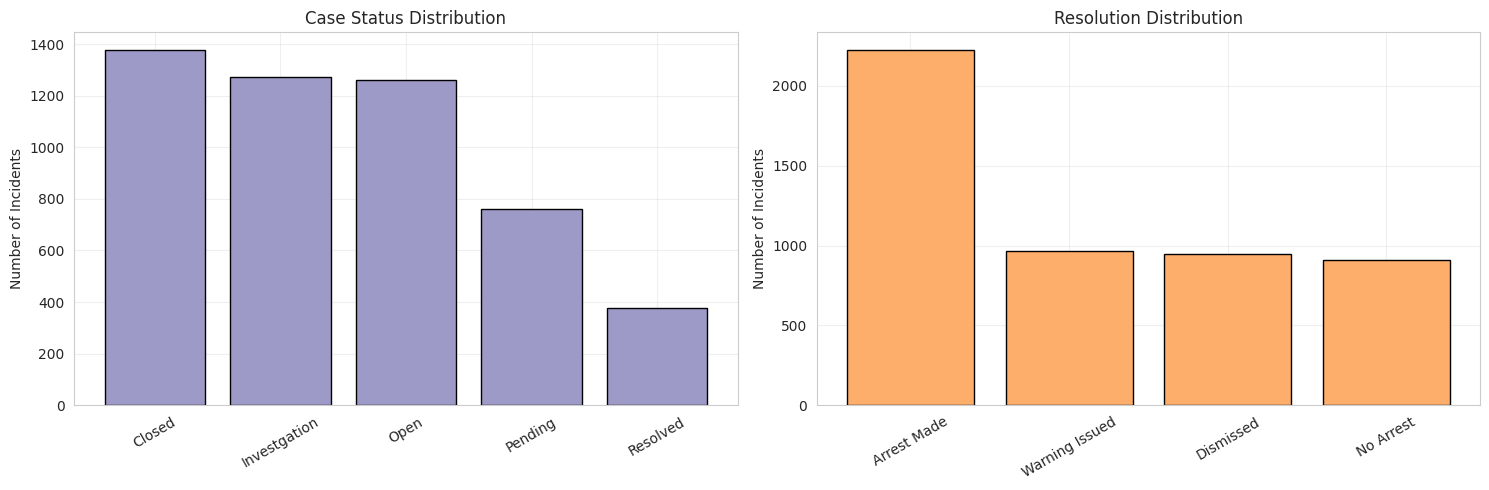

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

case_status_counts = df['case_status'].value_counts()
axes[0].bar(case_status_counts.index, case_status_counts.values, color='#9e9ac8', edgecolor='black')
axes[0].set_title('Case Status Distribution')
axes[0].set_ylabel('Number of Incidents')
axes[0].tick_params(axis='x', rotation=30)

resolution_counts = df['resolution'].value_counts()
axes[1].bar(resolution_counts.index, resolution_counts.values, color='#fdae6b', edgecolor='black')
axes[1].set_title('Resolution Distribution')
axes[1].set_ylabel('Number of Incidents')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### 7. Suspect Age & Victim Age Distributions

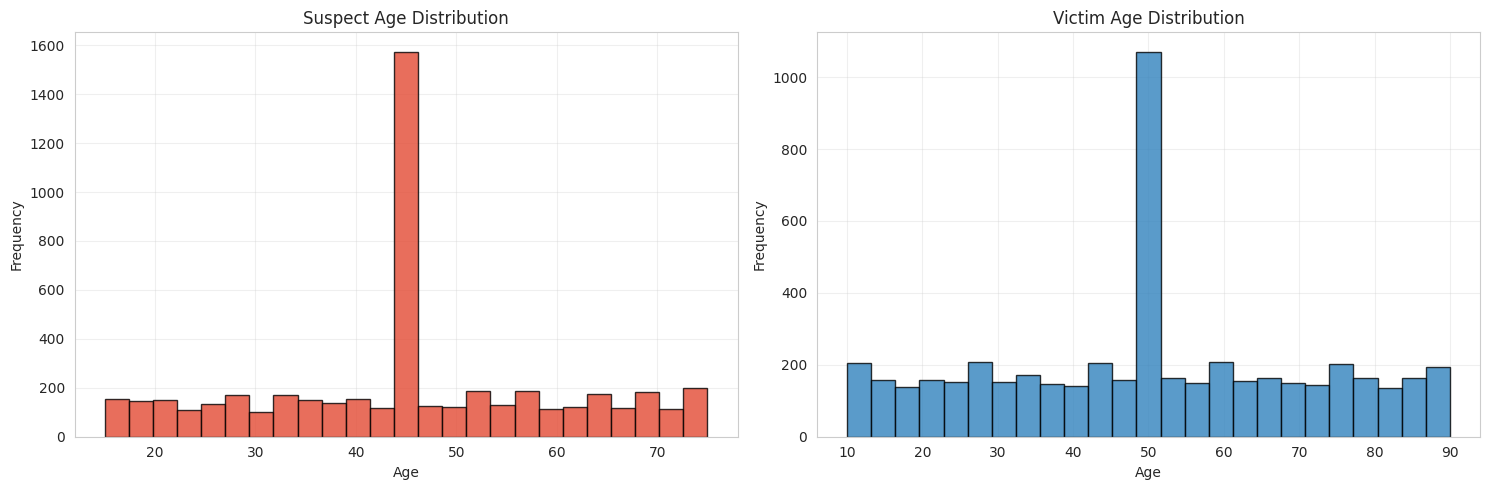

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(df['suspect_age'].dropna(), bins=25, color='#e34a33', edgecolor='black', alpha=0.8)
axes[0].set_title('Suspect Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

axes[1].hist(df['victim_age'].dropna(), bins=25, color='#3182bd', edgecolor='black', alpha=0.8)
axes[1].set_title('Victim Age Distribution')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### 8. Property Loss by Crime Type

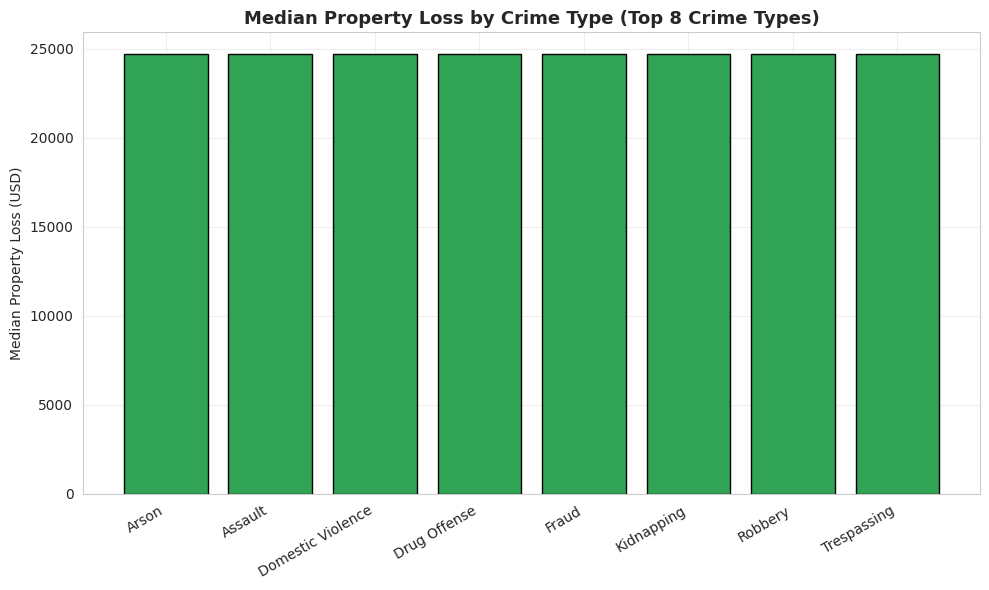

In [ ]:
top_crimes = df['crime_type'].value_counts().head(8).index
loss_by_crime = df[df['crime_type'].isin(top_crimes)].groupby('crime_type')['property_loss_usd'].median().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(loss_by_crime.index, loss_by_crime.values, color='#31a354', edgecolor='black')
ax.set_ylabel('Median Property Loss (USD)')
ax.set_title('Median Property Loss by Crime Type (Top 8 Crime Types)', fontsize=13, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 9. Weapon Used Breakdown

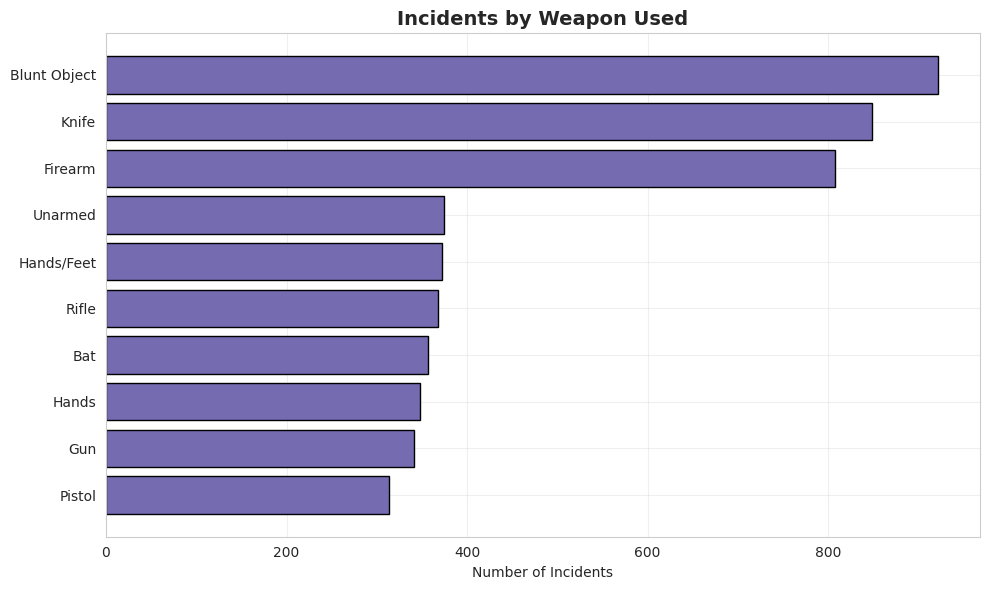

In [ ]:
weapon_counts = df['weapon_used'].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(weapon_counts.index[::-1], weapon_counts.values[::-1], color='#756bb1', edgecolor='black')
ax.set_xlabel('Number of Incidents')
ax.set_title('Incidents by Weapon Used', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 10. Heatmap: Incidents by Day of Week vs Hour

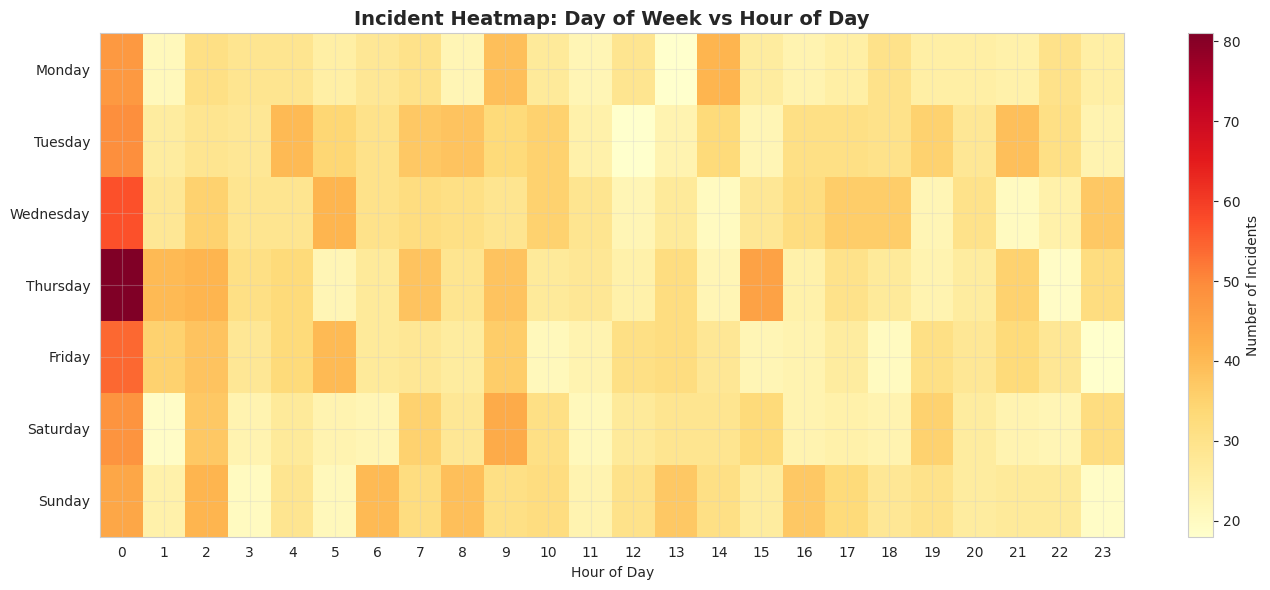

In [ ]:
df['incident_dow'] = df['incident_datetime'].dt.day_name()
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

heat_data = df.groupby(['incident_dow', 'incident_hour']).size().unstack(fill_value=0)
heat_data = heat_data.reindex(dow_order)

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(heat_data.values, cmap='YlOrRd', aspect='auto')
ax.set_yticks(range(len(dow_order)))
ax.set_yticklabels(dow_order)
ax.set_xticks(range(0, 24))
ax.set_xticklabels(range(0, 24))
ax.set_xlabel('Hour of Day')
ax.set_title('Incident Heatmap: Day of Week vs Hour of Day', fontsize=14, fontweight='bold')
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Number of Incidents')
plt.tight_layout()
plt.show()

### 11. Geographic Scatter of Incidents (Lat/Lon)

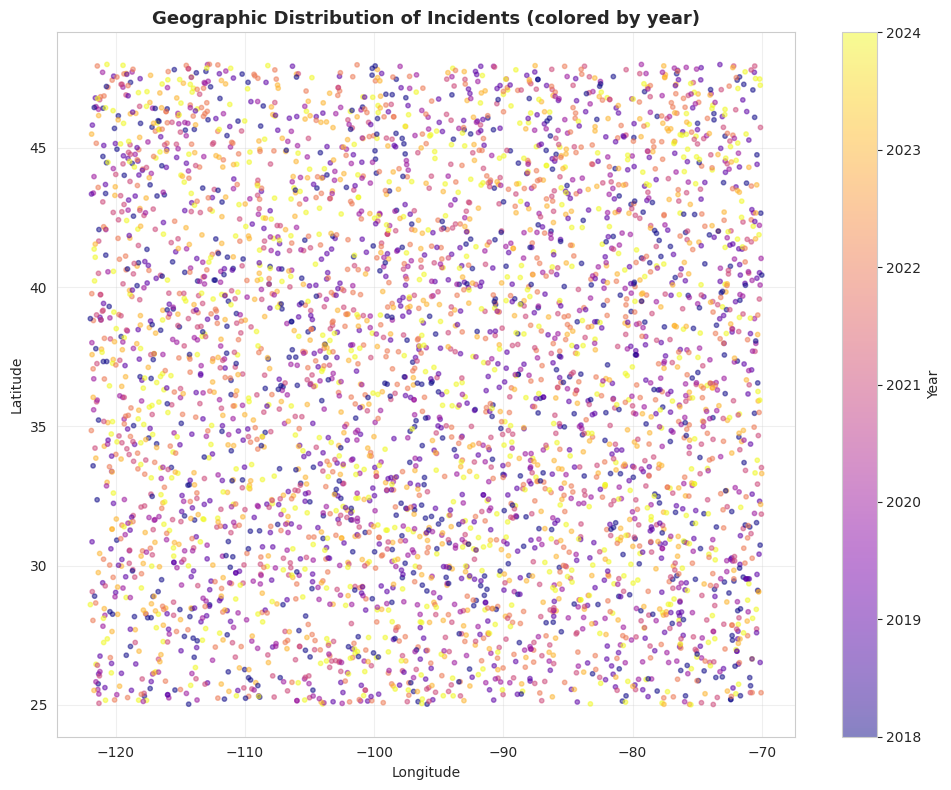

In [ ]:
geo = df.dropna(subset=['latitude', 'longitude'])

fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(geo['longitude'], geo['latitude'], c=geo['incident_year'],
                      cmap='plasma', alpha=0.5, s=10)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Geographic Distribution of Incidents (colored by year)', fontsize=13, fontweight='bold')
cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label('Year')
plt.tight_layout()
plt.show()

### 12. Suspect vs Victim Gender Comparison

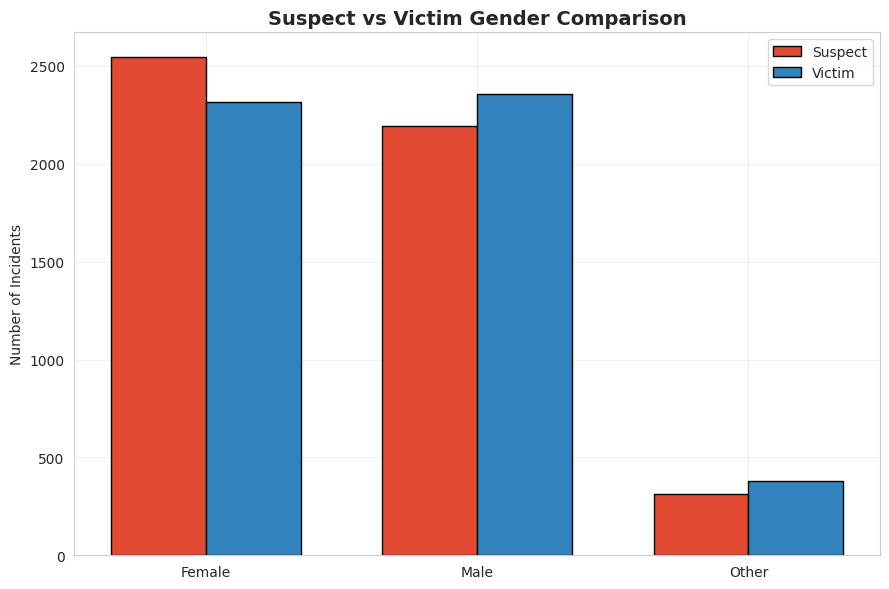

In [ ]:
suspect_gender_counts = df['suspect_gender'].value_counts()
victim_gender_counts = df['victim_gender'].value_counts()

genders = sorted(set(suspect_gender_counts.index) | set(victim_gender_counts.index))
suspect_vals = [suspect_gender_counts.get(g, 0) for g in genders]
victim_vals = [victim_gender_counts.get(g, 0) for g in genders]

x = np.arange(len(genders))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))
ax.bar(x - width/2, suspect_vals, width, label='Suspect', color='#e34a33', edgecolor='black')
ax.bar(x + width/2, victim_vals, width, label='Victim', color='#3182bd', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(genders)
ax.set_ylabel('Number of Incidents')
ax.set_title('Suspect vs Victim Gender Comparison', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### 13. Crime Classification: Felony vs. Misdemeanor

No prior version of this classification step exists in this notebook's history, so it is implemented here as new, documented code rather than guessed at. The logic combines a standard, simplified US-style legal classification of `crime_type` with two objective signals we already have (`severity` and `property_loss_usd`) for the crime types that are genuinely context-dependent. `crime_class_needs_review` is set to `True` whenever the automatic call relied on one of those thresholds (or the crime type was unmapped), flagging exactly the records a human analyst should double-check rather than leaving the whole dataset looking equally certain.

In [ ]:
# Crime types that are *almost always* charged as felonies, regardless
# of circumstances (violent crime, major property/security breach).
FELONY_CRIME_TYPES = {
    "Murder", "Manslaughter", "Homicide", "Sexual Assault", "Robbery",
    "Armed Robbery", "Kidnapping", "Abduction", "Arson", "Fire Setting",
    "Burglary", "Breaking & Entering", "Hacking", "Cybercrime", "Narcotics",
    "Drug Offense",
}

# Crime types that are *almost always* misdemeanors in their base form.
MISDEMEANOR_CRIME_TYPES = {
    "Vandalism", "Property Damage", "Graffiti", "Trespass", "Trespassing",
}

# Crime types whose class genuinely depends on context. These get
# reclassified using an objective threshold, and are ALWAYS flagged for
# review since an automatic call on these should be confirmed by a human.
SEVERITY_SENSITIVE_CRIME_TYPES = {
    "Assault", "Battery", "Assault & Battery", "Domestic Violence", "DUI",
}
VALUE_SENSITIVE_CRIME_TYPES = {
    "Theft", "Larceny", "Theft/Larceny", "Stealing",
    "Fraud", "Online Fraud", "Scam", "Deception", "Fraudulent Activity",
}
# Many US states draw the petty/grand theft (misdemeanor/felony) line
# somewhere between $1,000-$2,500; we use a conservative $2,500 threshold.
VALUE_FELONY_THRESHOLD_USD = 2500


def classify_crime(row):
    """Returns (crime_class, needs_review) for one incident row."""
    ctype = row["crime_type"]

    if ctype in FELONY_CRIME_TYPES:
        return "Felony", False
    if ctype in MISDEMEANOR_CRIME_TYPES:
        return "Misdemeanor", False

    if ctype in SEVERITY_SENSITIVE_CRIME_TYPES:
        is_felony = row["severity"] in ("High", "Critical")
        return ("Felony" if is_felony else "Misdemeanor"), True

    if ctype in VALUE_SENSITIVE_CRIME_TYPES:
        loss = row["property_loss_usd"]
        is_felony = pd.notna(loss) and loss >= VALUE_FELONY_THRESHOLD_USD
        return ("Felony" if is_felony else "Misdemeanor"), True

    # Unmapped/unknown crime_type: default to the less severe class, but
    # always flag for review since we have no real basis for the call.
    return "Misdemeanor", True


_classification = df.apply(classify_crime, axis=1, result_type="expand")
df["crime_class"] = _classification[0]
df["crime_class_needs_review"] = _classification[1]

print(df["crime_class"].value_counts())
print(
    f"\nFlagged for review: {df['crime_class_needs_review'].sum()} of "
    f"{len(df)} ({df['crime_class_needs_review'].mean() * 100:.1f}%)"
)

crime_class
Felony         3571
Misdemeanor    1479
Name: count, dtype: int64

Flagged for review: 1897 of 5050 (37.6%)


In [ ]:
df.to_csv("crime_incidents_cleaned2.csv", index=False)

### 12. Suspect vs Victim Gender Comparison

In [ ]:
pip install streamlit pandas matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


In [ ]:
df.to_csv("crime_incidents_cleaned.csv", index=False)